# Несколько записей одного процесса в EPDE: до и после

Здесь я сравниваю три состояния EPDE на одинаковых входах:

- **до** — последний коммит Тимура в основной ветке, с которого начиналась работа;
- **первая итерация** — первая опубликованная версия моих исправлений;
- **текущая** — эта ветка.

Что значит «несколько записей». Часто у одного процесса есть несколько независимых измерений: запуски с разными начальными условиями, разные роботы, разные куски длинной записи. Закон у них общий, а сетки, длины и шум свои. Раньше EPDE подбирал коэффициенты по каждой записи отдельно и затем усреднял их. Я добавил второй способ — общий подбор: один вектор коэффициентов ищется сразу по всем записям. Усреднение осталось способом по умолчанию.

Ноутбук отвечает на три вопроса:

1. Какие ошибки старых версий действительно воспроизводятся и исправлены ли они.
2. Не изменились ли результаты там, где старая версия работала правильно.
3. Когда общий подбор лучше усреднения, когда не даёт ничего, а когда хуже.

Тесты выполняются в ноутбуке заново на всех трёх версиях. Бенчмарк занимает около 20 минут, поэтому по умолчанию читаются сохранённые результаты; чтобы пересчитать их, задайте переменную окружения `MULTISAMPLE_RERUN=1`.

In [1]:
import json, os, re, shutil, subprocess, sys, tempfile
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

def find_repo(start):
    for path in [start, *start.parents]:
        if (path / 'epde' / '__init__.py').exists() and (path / 'projects' / 'multisample').exists():
            return path
    raise RuntimeError('Run the notebook from inside the EPDE checkout.')

REPO = find_repo(Path.cwd().resolve())
BENCH_DIR = REPO / 'projects' / 'multisample'
RESULTS = BENCH_DIR / 'results' / '2026-11-13' / 'before_after'
RERUN = os.environ.get('MULTISAMPLE_RERUN', '0') == '1'
VERSIONS = {
    'до': '8690035e90b234b34ed5a2fb0bb8e4a814dcbdf7',
    'первая итерация': '9b9cd7ceafeadd5e9f77e80bf21087fc9089d4ae',
    'текущая': None,
}
WORK = Path(tempfile.gettempdir()) / 'epde_multisample_versions'

def checkout(commit):
    # A detached worktree per old commit; the current version is this checkout.
    if commit is None:
        return REPO
    path = WORK / commit[:8]
    if not (path / 'epde' / '__init__.py').exists():
        WORK.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'worktree', 'prune'], cwd=REPO, check=True)
        subprocess.run(['git', 'worktree', 'add', '--force', '--detach', str(path), commit],
                       cwd=REPO, check=True, capture_output=True)
    return path

TREES = {name: checkout(commit) for name, commit in VERSIONS.items()}
for name, path in TREES.items():
    commit = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], cwd=path, text=True).strip()
    print(f'{name:>16}: коммит {commit}')

              до: коммит 8690035e
 первая итерация: коммит 9b9cd7ce
         текущая: коммит 37ba4dea


## 1. Тесты текущей версии на старых версиях

Беру все тесты, которые я написал для нескольких записей, и запускаю их без изменений на каждой версии. Каждый тест описывает правильное поведение, поэтому падение на старой версии означает, что этого поведения там не было.

Падения я делю на три вида:

- **нет новой возможности** — тест обращается к настройке или модулю, которых в старой версии ещё нет; это не ошибка старой версии;
- **нет проверки входа** — старая версия молча принимает неверные данные, которые теперь отклоняются с понятным сообщением;
- **ошибка вычисления** — старая версия падает или даёт неверный результат на допустимых данных. Это настоящие исправленные ошибки.

In [2]:
TEST_FILES = sorted(p.name for p in (REPO / 'tests' / 'unit').glob('test_multisample_*.py'))
JUNIT = Path(tempfile.gettempdir()) / 'epde_multisample_junit'
JUNIT.mkdir(exist_ok=True)

def run_tests(name, tree):
    if tree != REPO:
        for file in TEST_FILES:
            shutil.copy(REPO / 'tests' / 'unit' / file, tree / 'tests' / 'unit' / file)
    report = JUNIT / f'{abs(hash(name))}.xml'
    env = dict(os.environ, PYTHONPATH=str(tree))
    subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider',
                    '--continue-on-collection-errors', f'--junitxml={report}',
                    *[f'tests/unit/{f}' for f in TEST_FILES]],
                   cwd=tree, env=env, capture_output=True, text=True)
    return report

NEW_FEATURE = ("No module named 'epde.operators.common.multisample'", "Unknown search-config parameter(s) ['multisample",
               "has no attribute 'multisample", 'EpdeMultisample.__init__() got an unexpected keyword')

def category(message):
    if any(marker in message for marker in NEW_FEATURE):
        return 'нет новой возможности'
    if message.startswith(('Failed: DID NOT RAISE', 'Failed: DID NOT WARN', 'AssertionError: Regex pattern did not match')):
        return 'нет проверки входа'
    return 'ошибка вычисления'

rows = []
for name, tree in TREES.items():
    root = ET.parse(run_tests(name, tree)).getroot()
    for case in root.iter('testcase'):
        problem = case.find('failure')
        if problem is None:
            problem = case.find('error')
        message = '' if problem is None else (problem.get('message') or '')
        # A file that fails to import reports one collection error named after the file.
        found = re.search(r'test_multisample_(\w+)', case.get('classname', '') + ' ' + (case.get('name') or ''))
        file = found.group(1) if found else 'collection'
        rows.append({'версия': name, 'файл': file,
                     'тест': case.get('name'),
                     'итог': 'прошёл' if problem is None else category(message),
                     'сообщение': message.splitlines()[0][:140] if message else ''})
tests = pd.DataFrame(rows)
order = ['прошёл', 'нет новой возможности', 'нет проверки входа', 'ошибка вычисления']
summary = (tests.pivot_table(index='версия', columns='итог', values='тест', aggfunc='count', fill_value=0)
           .reindex(index=list(TREES), columns=order, fill_value=0))
summary

итог,прошёл,нет новой возможности,нет проверки входа,ошибка вычисления
версия,,,,
до,8,46,23,52
первая итерация,106,0,3,39
текущая,148,0,0,0


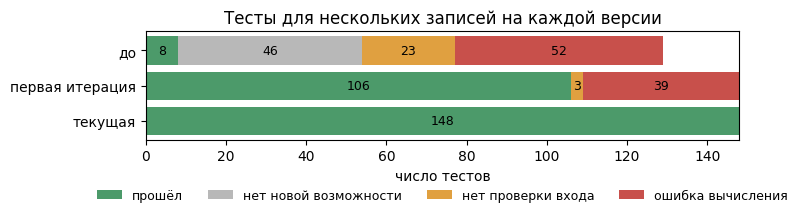

In [3]:
colors = {'прошёл': '#4C9A6A', 'нет новой возможности': '#B8B8B8',
          'нет проверки входа': '#E0A040', 'ошибка вычисления': '#C8504B'}
fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(len(summary))
for column in order:
    ax.barh(summary.index, summary[column], left=left, color=colors[column], label=column)
    for i, (start, width) in enumerate(zip(left, summary[column])):
        if width:
            ax.text(start + width / 2, i, int(width), ha='center', va='center', fontsize=9)
    left += summary[column].to_numpy()
ax.invert_yaxis()
ax.set_xlabel('число тестов')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.35), frameon=False, fontsize=9)
ax.set_title('Тесты для нескольких записей на каждой версии')
plt.tight_layout()
plt.show()

Ниже — ошибки вычисления по группам тестов. Это главное в разделе: какие случаи старые версии считали неверно.

In [4]:
errors = tests[tests['итог'] == 'ошибка вычисления']
(errors.pivot_table(index='файл', columns='версия', values='тест', aggfunc='count', fill_value=0)
       .reindex(columns=[c for c in TREES if c in errors['версия'].unique()]))

версия,до,первая итерация
файл,,
api,1,0
domain,22,0
fill,1,0
lifecycle,27,27
numerics,1,12


In [5]:
# Errors the first iteration still had and the current version fixes.
second = tests[(tests['версия'] == 'первая итерация') & (tests['итог'] != 'прошёл')]
second[['файл', 'тест', 'итог', 'сообщение']].sort_values(['файл', 'тест']).reset_index(drop=True)

,файл,тест,итог,сообщение
0,domain,test_equal_row_count_does_not_make_an_arbitrary_mask_rectangular[hole-None],нет проверки входа,Failed: DID NOT RAISE ValueError
1,domain,test_equal_row_count_does_not_make_an_arbitrary_mask_rectangular[shifted-None],нет проверки входа,Failed: DID NOT RAISE ValueError
2,lifecycle,test_invalid_stored_upload_does_not_poison_a_later_valid_upload,нет проверки входа,Failed: DID NOT RAISE KeyError
3,lifecycle,test_mutating_derivative_order_list_is_a_new_build_request[build],ошибка вычисления,"KeyError: ('d^2u/dx0^2', (1.0,))"
4,lifecycle,test_mutating_derivative_order_list_is_a_new_build_request[create_pool],ошибка вычисления,"KeyError: ('d^2u/dx0^2', (1.0,))"
5,lifecycle,test_nonfinite_edit_to_the_original_field_does_not_corrupt_the_sample,ошибка вычисления,"ValueError: Trajectory 7, variable 'u': data must contain finite real numbers."
6,lifecycle,test_observations_remain_the_creation_snapshot[first-entries],ошибка вычисления,AssertionError:
7,lifecycle,test_observations_remain_the_creation_snapshot[first-mapping],ошибка вычисления,AssertionError:
8,lifecycle,test_observations_remain_the_creation_snapshot[force-entries],ошибка вычисления,AssertionError:
9,lifecycle,test_observations_remain_the_creation_snapshot[force-mapping],ошибка вычисления,AssertionError:


## 2. Одинаковые задания на старой и новой версии

Тесты проверяют отдельные места. Теперь сравниваю поведение целиком: один и тот же бенчмарк запускается на версии «до» и на текущей. Старая версия умеет только усреднять, поэтому на ней запускаются все задания в режиме усреднения.

Задания бенчмарка:

- **подгонка заданной структуры** — EPDE получает правильный набор членов и подбирает только коэффициенты;
- **выбор из заданных членов** — EPDE выбирает члены из переданного набора;
- **полный поиск** — эволюционный поиск структуры, пять сидов.

Данные синтетические, с известным законом. Для каждой задачи одна целая запись с новыми начальными условиями отложена: она не участвует ни в обучении, ни в выборе модели и служит только для проверки.

In [6]:
if RERUN:
    for label, extra in (('current', []), ('baseline', ['--modes', 'mean', '--epde-root', str(TREES['до'])])):
        subprocess.run([sys.executable, str(BENCH_DIR / 'benchmark.py'), '--suite', 'all', '--workers', '3',
                        '--output', str(RESULTS / f'{label}.json'), *extra], cwd=REPO, check=True)

def load(label):
    report = json.loads((RESULTS / f'{label}.json').read_text())
    rows = []
    for result in report['results']:
        spec = result['spec']
        model = next((m for m in result['models'] if m['model_id'] == result.get('selected_model_id')), None)
        equations = model['equations'] if model else []
        support = [e['support_exact'] for e in equations]
        errors = [e['coefficient_error'] for e in equations]
        holdout = [s['relative_l2'] for e in equations for s in e['holdout_residuals'] if s['relative_l2'] is not None]
        rows.append({
            'задача': spec['scenario'], 'этап': spec['stage'], 'производные': spec['derivatives'],
            'шум': spec['noise'], 'форма': spec['evaluation_form'], 'сид': spec['seed'],
            'режим': spec['multisample_mode'], 'веса': spec['weighting'], 'плотность': spec.get('density'),
            'статус': result['status'],
            'структура верна': (all(s is True for s in support) if support and None not in support else np.nan),
            'верное на фронте': bool(result.get('truth_on_front')),
            'ошибка коэффициентов': max(errors) if errors and None not in errors else np.nan,
            'невязка на отложенной записи': float(np.mean(holdout)) if holdout else np.nan,
            'уравнение': ' | '.join(e['text'] for e in equations),
            'сообщение': result.get('error') or result.get('reason') or '',
        })
    return report, pd.DataFrame(rows)

current_report, current = load('current')
baseline_report, baseline = load('baseline')
print('текущая версия:', current_report['metadata']['git_head'][:8], '—', len(current), 'заданий')
print('версия «до»:', baseline_report['metadata']['git_head'][:8], '—', len(baseline), 'заданий')
pd.concat({'до': baseline['статус'].value_counts(), 'текущая, усреднение':
           current[current['режим'] == 'mean']['статус'].value_counts(),
           'текущая, общий подбор': current[current['режим'] == 'joint']['статус'].value_counts()},
          axis=1).fillna(0).astype(int)

текущая версия: 2b30d08e — 176 заданий
версия «до»: 8690035e — 85 заданий


,до,"текущая, усреднение","текущая, общий подбор"
статус,,,
ok,84,84,91
no_candidate,1,1,0


In [7]:
KEY = ['задача', 'этап', 'производные', 'шум', 'форма', 'сид', 'веса', 'плотность']
pair = baseline.merge(current[current['режим'] == 'mean'], on=KEY, suffixes=(' до', ' сейчас'))
pair['одно и то же уравнение'] = pair['уравнение до'] == pair['уравнение сейчас']
print('пар заданий:', len(pair))
print('совпало уравнение:', int(pair['одно и то же уравнение'].sum()))
changed = pair[~pair['одно и то же уравнение']]
changed[KEY[:5] + ['сид', 'статус до', 'статус сейчас', 'структура верна до', 'структура верна сейчас',
                   'сообщение до']].reset_index(drop=True)

пар заданий: 85
совпало уравнение: 85


,задача,этап,производные,шум,форма,сид,статус до,статус сейчас,структура верна до,структура верна сейчас,сообщение до


## 3. Усреднение против общего подбора

Теперь сравниваю два режима внутри текущей версии. Это отдельный вопрос: исправления из разделов 1 и 2 касаются надёжности, а здесь проверяется сам способ объединения записей.

Задачи:

| Задача | Закон | Что проверяется |
|---|---|---|
| логистическое уравнение | $u_t = 1.2u - 0.6u^2$ | нелинейный член, разные начальные условия |
| связанная система | $u_t=-0.2u+v,\; v_t=-u-0.2v$ | две переменные |
| реакция–диффузия | $u_t = -0.2u + 0.1u_{xx}$ | на каждой записи одна мода, поэтому $u_{xx}=-k^2u$ и закон по одной записи не определяется |
| теплопроводность | $u_t = 0.1u_{xx}$ | та же вырожденность, но правильный закон самый простой |
| перенос с диффузией | $u_t = -0.5u_x + 0.1u_{xx}$ | вырожденность при наличии переноса |
| реакция–диффузия, богатые записи | как выше | контроль: в каждой записи уже по две моды |

Задачи с тремя последними строками и контроль взяты из моего прошлого исследования нескольких траекторий в ветке демо-сайта, только теперь поиск идёт настоящим EPDE.

Показатель «структура верна» — найден ровно правильный набор членов. Ошибка коэффициентов — относительная ошибка вектора коэффициентов с учётом лишних членов. Невязка на отложенной записи — относительная норма невязки уравнения на записи, которую EPDE не видел.

In [8]:
discovery = current[current['этап'] == 'discovery'].copy()
discovery['условия'] = discovery.apply(
    lambda r: ('точные производные' if r['производные'] == 'analytic' else
               'реальные данные' if r['шум'] == 0 else f"шум {r['шум']:.0%}")
              + (', слабая форма' if r['форма'] == 'weak' else ''), axis=1)
table = (discovery.groupby(['задача', 'условия', 'режим'])
         .agg(запусков=('сид', 'size'), верных=('структура верна', 'sum'),
              на_фронте=('верное на фронте', 'sum'),
              ошибка_коэфф=('ошибка коэффициентов', 'median'),
              невязка=('невязка на отложенной записи', 'median'))
         .unstack('режим'))
table['верных'] = table['верных'].astype(int)
table['на_фронте'] = table['на_фронте'].astype(int)
table.style.format({c: '{:.2e}' for c in table.columns if c[0] in ('ошибка_коэфф', 'невязка')})

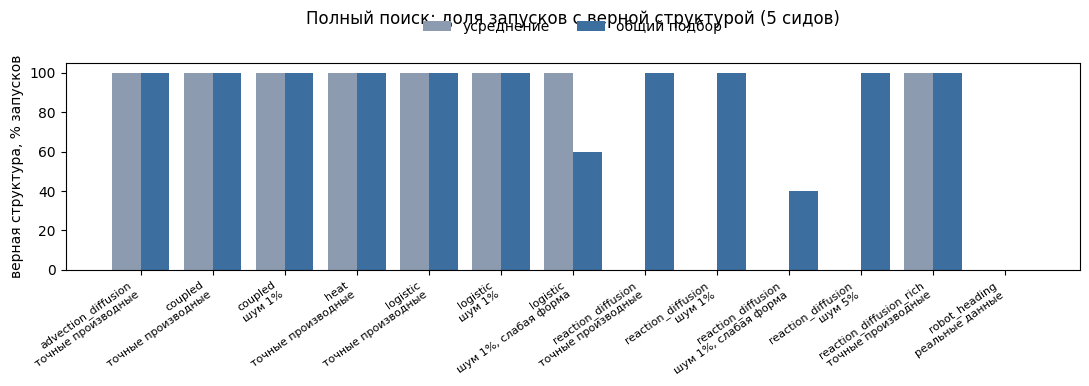

In [9]:
rates = (discovery.groupby(['задача', 'условия', 'режим'])['структура верна'].mean().unstack('режим'))
labels = [f'{t}\n{c}' for t, c in rates.index]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(rates))
ax.bar(x - 0.2, rates['mean'] * 100, 0.4, label='усреднение', color='#8C9BB0')
ax.bar(x + 0.2, rates['joint'] * 100, 0.4, label='общий подбор', color='#3C6E9F')
ax.set_xticks(x, labels, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('верная структура, % запусков')
ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.08))
ax.set_title('Полный поиск: доля запусков с верной структурой (5 сидов)', pad=28)
plt.tight_layout()
plt.show()

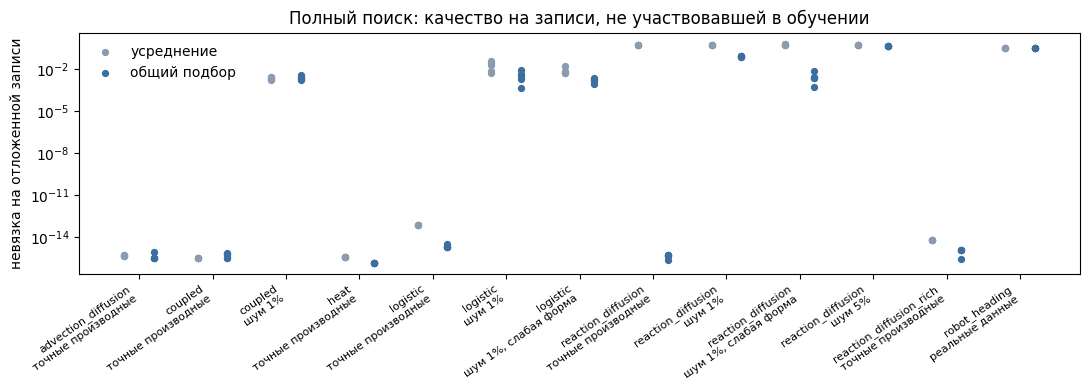

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
groups = list(rates.index)
for offset, mode, color in ((-0.2, 'mean', '#8C9BB0'), (0.2, 'joint', '#3C6E9F')):
    for i, group in enumerate(groups):
        values = discovery[(discovery['задача'] == group[0]) & (discovery['условия'] == group[1])
                           & (discovery['режим'] == mode)]['невязка на отложенной записи'].dropna()
        ax.scatter(np.full(len(values), i + offset), values, color=color, s=18,
                   label=('усреднение' if mode == 'mean' else 'общий подбор') if i == 0 else None)
ax.set_yscale('log')
ax.set_xticks(np.arange(len(groups)), labels, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('невязка на отложенной записи')
ax.legend(frameon=False)
ax.set_title('Полный поиск: качество на записи, не участвовавшей в обучении')
plt.tight_layout()
plt.show()

### Подгонка заданной структуры и контрольные случаи

Здесь EPDE получает правильные члены, поэтому видно только, как считаются коэффициенты. Два контроля:

- **противоречивые записи** — у записей разные законы ($u_t=-0.4u$ и $u_t=-u$), общего закона нет. Правильное поведение — заметная невязка, а не ложная точность;
- **плотность сетки** — вторая запись измерена в четыре раза чаще. При равном весе записей коэффициент не должен меняться, при равном весе точек он сдвигается к более плотной записи.

In [11]:
fixed = current[current['этап'].isin(['fixed', 'assignment'])]
show = fixed[KEY[:5] + ['режим', 'веса', 'плотность', 'статус', 'структура верна', 'ошибка коэффициентов',
                        'невязка на отложенной записи']].sort_values(['этап', 'задача', 'производные', 'шум', 'режим'])
show.reset_index(drop=True).style.format({'ошибка коэффициентов': '{:.2e}', 'невязка на отложенной записи': '{:.2e}'},
                                         na_rep='—')

,задача,этап,производные,шум,форма,режим,веса,плотность,статус,структура верна,ошибка коэффициентов,невязка на отложенной записи
0,logistic,assignment,analytic,0.000000,strong,joint,samples,—,ok,True,1.11e-15,1.52e-15
1,logistic,assignment,analytic,0.000000,strong,mean,samples,—,ok,True,4.55e-14,7.24e-14
2,reaction_diffusion,assignment,analytic,0.000000,strong,joint,samples,—,ok,False,9.89e-01,5.01e-01
3,reaction_diffusion,assignment,analytic,0.000000,strong,mean,samples,—,ok,False,1.05e+00,6.57e-01
4,advection_diffusion,fixed,analytic,0.000000,strong,joint,samples,—,ok,True,2.43e-16,3.36e-16
5,advection_diffusion,fixed,analytic,0.000000,strong,mean,samples,—,ok,True,2.19e-16,4.39e-16
6,affine,fixed,analytic,0.000000,strong,joint,samples,—,ok,True,1.54e-16,2.23e-16
7,affine,fixed,analytic,0.000000,strong,mean,samples,—,ok,True,1.38e-15,3.08e-15
8,contradictory,fixed,analytic,0.000000,strong,joint,samples,—,ok,—,—,1.69e-01
9,contradictory,fixed,analytic,0.000000,strong,mean,samples,—,ok,—,—,1.73e-16


In [12]:
controls = pd.DataFrame(current_report['summary']['controls'])
controls

,control,run_id,maximum_clean_training_residual,cannot_fit_both_exactly,weighting,coarse_coefficient,refined_coefficient,absolute_change,expected_coarse,expected_refined,matches_analytic_expectation
0,contradictory_laws,026_contradictory_fixed_analytic_mean_samples_strong_base_noise0_seed0,0.750000,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,contradictory_laws,027_contradictory_fixed_analytic_joint_samples_strong_base_noise0_seed0,0.453694,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sampling_density,NaN,NaN,NaN,samples,-2.5,-2.5,8.881784e-16,-2.5,-2.5,True
3,sampling_density,NaN,NaN,NaN,points,-2.5,-3.4,9.000000e-01,-2.5,-3.4,True


### Как из фронта выбирается одна модель

EPDE возвращает не одно уравнение, а фронт: набор уравнений, где ни одно не лучше другого сразу по невязке и по нестабильности. Для сравнения нужно выбрать одно. Сначала я выбирал уравнение с наименьшей невязкой на обучающих данных. На шумных данных это правило подводит: при общем подборе на фронте почти всегда лежат два уравнения — правильное и оно же с крошечным свободным членом порядка $10^{-3}$, подогнанным под шум. Невязки у них совпадают до шестого знака, а нестабильность у второго в 20–70 раз выше.

Теперь среди уравнений, невязка которых не более чем на 0,1 % хуже лучшей, выбирается самое стабильное. Правило использует только обучающие данные. Ниже — фронт одного такого запуска.

In [13]:
example = next(r for r in current_report['results']
               if r['spec']['scenario'] == 'logistic' and r['spec']['stage'] == 'discovery'
               and r['spec']['derivatives'] == 'fd' and r['spec']['evaluation_form'] == 'strong'
               and r['spec']['multisample_mode'] == 'joint' and r['spec']['seed'] == 0)
front = pd.DataFrame([{'уравнение': m['equations'][0]['text'].split(' = ')[0],
                       'невязка': m['training_selection_score'],
                       'нестабильность': m['training_instability'],
                       'выбрано': m['model_id'] == example['selected_model_id'],
                       'верная структура': m['equations'][0]['support_exact']} for m in example['models']])
front.style.format({'невязка': '{:.6f}', 'нестабильность': '{:.3f}'})

,уравнение,невязка,нестабильность,выбрано,верная структура
0,1.2031173230038152 * u{power: 1.0} + -0.6015217904027347 * u{power: 2.0},0.348401,0.281,True,True
1,1.2046395482160175 * u{power: 1.0} + -0.6020074101407015 * u{power: 2.0} + -0.0010367545435537415,0.348401,6.259,False,False


## 4. Пример: реакция–диффузия

Самый показательный случай. Закон $u_t = -0.2u + 0.1u_{xx}$. В первой обучающей записи одна пространственная мода с $k=1$, во второй — с $k=2$. Внутри одной записи $u_{xx} = -k^2u$, поэтому уравнение $u_t = c\,u$ с подходящим $c$ описывает её точно, и по одной записи нельзя отличить реакцию от диффузии. Только две записи вместе однозначно задают оба коэффициента.

При усреднении каждая запись подбирается отдельно, поэтому поиск находит более простое уравнение $u_t = c\,u$ с разными $c$, а среднее этих $c$ не подходит ни одной записи. Общий подбор сразу видит обе записи.

Отложенная запись содержит смесь мод $k=1$ и $k=3$ на новой сетке, поэтому проверяет перенос закона, а не повторение обучающих данных.

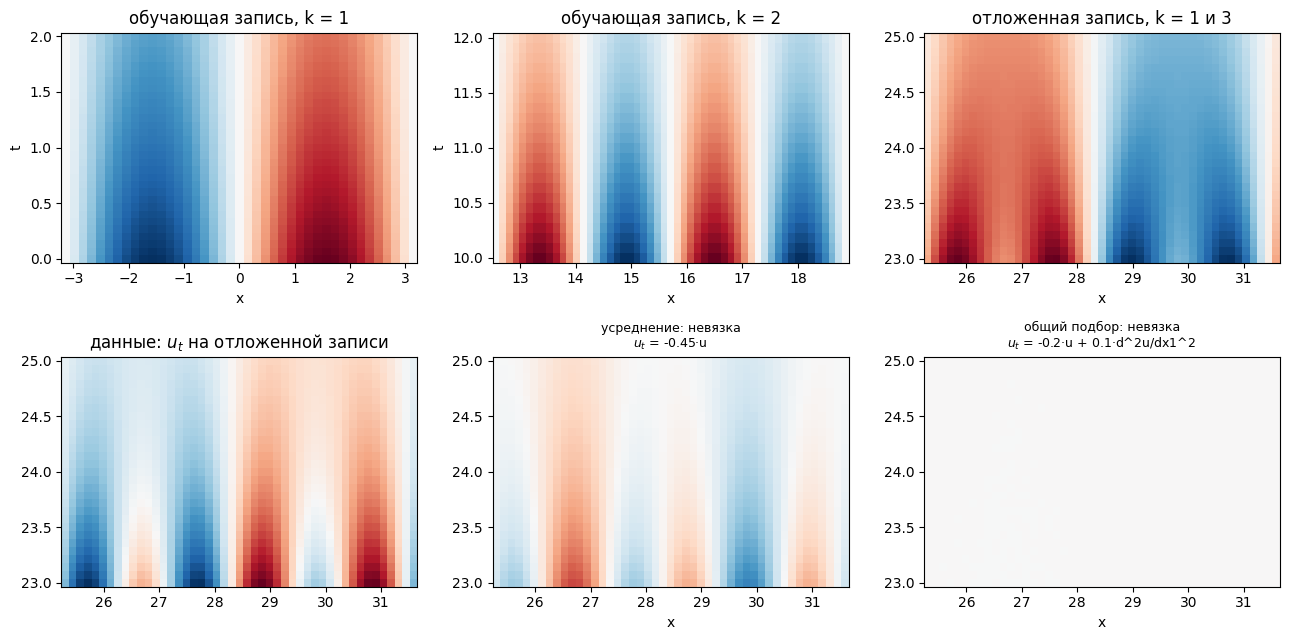

In [14]:
sys.path.insert(0, str(BENCH_DIR))
import benchmark
case = benchmark.make_case({'scenario': 'reaction_diffusion', 'noise': 0.0, 'seed': 0})

def run_of(mode, seed=0):
    row = current[(current['задача'] == 'reaction_diffusion') & (current['этап'] == 'discovery')
                  & (current['производные'] == 'analytic') & (current['режим'] == mode) & (current['сид'] == seed)]
    return row.iloc[0]

def coefficients(mode, seed=0):
    result = next(r for r in current_report['results']
                  if r['spec']['scenario'] == 'reaction_diffusion' and r['spec']['stage'] == 'discovery'
                  and r['spec']['derivatives'] == 'analytic' and r['spec']['multisample_mode'] == mode
                  and r['spec']['seed'] == seed)
    model = next(m for m in result['models'] if m['model_id'] == result['selected_model_id'])
    return model['equations'][0]['canonical_coefficients']

def predict(coefs, tokens):
    total = np.zeros_like(tokens['u'])
    for key, value in coefs.items():
        total += value * (1.0 if key == '1' else tokens[key])
    return total

held = case['holdout'][0]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, record in zip(axes[0, :2], case['train']):
    t, x = record['axes']
    im = ax.pcolormesh(x, t, record['clean_fields']['u'], shading='auto', cmap='RdBu_r')
    ax.set_title(f"обучающая запись, k = {record['parameters']['modes'][0][0]}")
    ax.set_xlabel('x'); ax.set_ylabel('t')
t, x = held['axes']
axes[0, 2].pcolormesh(x, t, held['clean_fields']['u'], shading='auto', cmap='RdBu_r')
axes[0, 2].set_title('отложенная запись, k = 1 и 3'); axes[0, 2].set_xlabel('x')
target = held['clean_tokens']['du/dx0']
scale = np.abs(target).max()
axes[1, 0].pcolormesh(x, t, target, shading='auto', cmap='RdBu_r', vmin=-scale, vmax=scale)
axes[1, 0].set_title('данные: $u_t$ на отложенной записи')
for ax, mode, name in ((axes[1, 1], 'mean', 'усреднение'), (axes[1, 2], 'joint', 'общий подбор')):
    coefs = coefficients(mode)
    residual = target - predict(coefs, held['clean_tokens'])
    ax.pcolormesh(x, t, residual, shading='auto', cmap='RdBu_r', vmin=-scale, vmax=scale)
    text = ' + '.join(f'{v:.3g}·{k}' for k, v in coefs.items() if abs(v) > 1e-8)
    ax.set_title(f'{name}: невязка\n$u_t$ = {text}', fontsize=9)
    ax.set_xlabel('x')
plt.tight_layout()
plt.show()

Цвета нижнего ряда в одной шкале: чем бледнее невязка, тем лучше уравнение объясняет запись, которой не было в обучении.

## 5. Реальные данные: вращение робота

Последняя проверка — на настоящей записи. Беру робота 3 из записи с 30 роботами, которая лежит в репозитории EPDE, и описываю его направление двумя величинами: $u=\cos\varphi$ и $v=\sin\varphi$. Если робот вращается с постоянной частотой $\omega$, то $u_t=-\omega v$ и $v_t=\omega u$.

Шесть отрезков по 2 секунды из первой минуты — независимые записи для обучения. Шесть таких же отрезков из второй минуты отложены для проверки. Производные EPDE считает сам по измеренным углам. Опорная частота — наклон фазы за первую минуту. Это ориентир, а не точный ответ: при столкновениях с соседями частота меняется.

In [15]:
robot = current[current['задача'] == 'robot_heading']
robot[['этап', 'режим', 'сид', 'статус', 'структура верна', 'верное на фронте', 'ошибка коэффициентов',
       'невязка на отложенной записи', 'уравнение']].sort_values(['этап', 'режим', 'сид']).reset_index(drop=True)

,этап,режим,сид,статус,структура верна,верное на фронте,ошибка коэффициентов,невязка на отложенной записи,уравнение
0,discovery,joint,0,ok,False,True,0.041761,0.310485,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.321625877747502 * u{power: 1.0} + ...
1,discovery,joint,1,ok,False,True,0.041761,0.310485,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.321625877747502 * u{power: 1.0} + ...
2,discovery,joint,2,ok,False,True,0.041761,0.310485,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.321625877747502 * u{power: 1.0} + ...
3,discovery,joint,3,ok,False,True,0.041761,0.310485,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.321625877747502 * u{power: 1.0} + ...
4,discovery,joint,4,ok,False,True,0.041761,0.310485,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.321625877747502 * u{power: 1.0} + ...
5,discovery,mean,0,ok,False,True,0.043651,0.311603,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.32874137463353 * u{power: 1.0} + -...
6,discovery,mean,1,ok,False,True,0.043651,0.311603,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.32874137463353 * u{power: 1.0} + -...
7,discovery,mean,2,ok,False,True,0.043651,0.311603,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.32874137463353 * u{power: 1.0} + -...
8,discovery,mean,3,ok,False,True,0.043651,0.311603,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.32874137463353 * u{power: 1.0} + -...
9,discovery,mean,4,ok,False,True,0.043651,0.311603,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.32874137463353 * u{power: 1.0} + -...


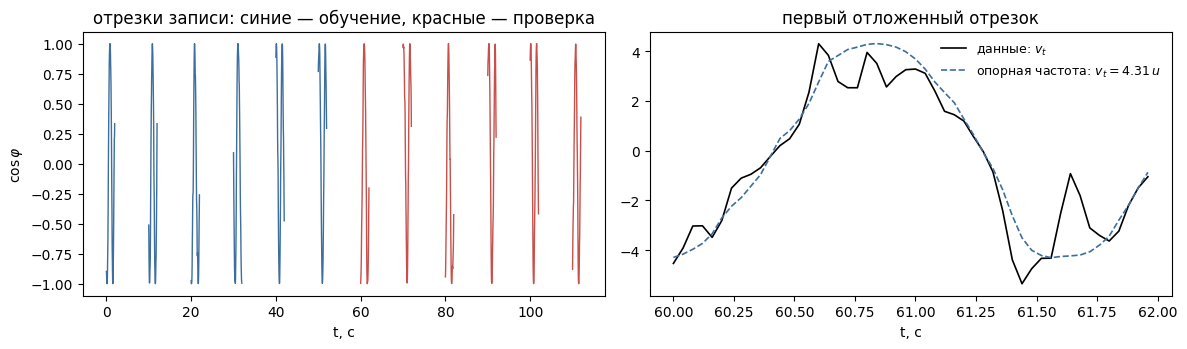

 mean: -4.359587477374821 * v{power: 1.0} = du/dx0{power: 1.0} | 4.328474831875724 * u{power: 1.0} = dv/dx0{power: 1.0}
joint: -4.352669843313463 * v{power: 1.0} = du/dx0{power: 1.0} | 4.3251185826386305 * u{power: 1.0} = dv/dx0{power: 1.0}


In [16]:
robot_case = benchmark.make_case({'scenario': 'robot_heading', 'noise': 0.0, 'seed': 0})
omega = robot_case['truth']['v']['u']
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for record in robot_case['train'] + robot_case['holdout']:
    t = record['axes'][0]
    held = record in robot_case['holdout']
    axes[0].plot(t, record['clean_fields']['u'], color='#C8504B' if held else '#3C6E9F', lw=1)
axes[0].set_xlabel('t, с'); axes[0].set_ylabel(r'$\cos\varphi$')
axes[0].set_title('отрезки записи: синие — обучение, красные — проверка')
fits = {}
for mode in ('mean', 'joint'):
    row = robot[(robot['этап'] == 'fixed') & (robot['режим'] == mode)].iloc[0]
    fits[mode] = row['уравнение']
record = robot_case['holdout'][0]
t = record['axes'][0]
axes[1].plot(t, record['clean_tokens']['dv/dx0'], color='black', lw=1.2, label=r'данные: $v_t$')
axes[1].plot(t, omega * record['clean_tokens']['u'], '--', color='#3C6E9F', lw=1.2,
             label=rf'опорная частота: $v_t={omega:.2f}\,u$')
axes[1].set_xlabel('t, с'); axes[1].legend(frameon=False, fontsize=9)
axes[1].set_title('первый отложенный отрезок')
plt.tight_layout()
plt.show()
for mode, text in fits.items():
    print(f'{mode:>5}: {text}')

## 6. Итоги

**Надёжность.** Тесты из раздела 1 показывают, сколько ошибок вычисления было в версии «до» и сколько оставалось после первой итерации; текущая версия проходит все тесты. Бенчмарк из раздела 2 показывает, что в режиме усреднения текущая версия даёт те же уравнения, что версия «до», во всех общих заданиях. Значит, старые сценарии не изменились, а исправления касаются случаев, которые раньше считались неверно или падали.

**Когда общий подбор помогает.** Когда отдельная запись не определяет закон, а все вместе — определяют. На реакции–диффузии с одной модой в каждой записи общий подбор находит верный закон во всех запусках, включая шум 1 % и 5 %, а усреднение — ни в одном.

**Когда не даёт ничего.** Если каждая запись уже определяет закон (логистическое уравнение, связанная система, теплопроводность, перенос с диффузией, реакция–диффузия с двумя модами в каждой записи, вращение робота), оба режима находят одно и то же. На теплопроводности и переносе с диффузией одна запись формально вырождена, но верный закон в них самый простой, поэтому усреднение тоже справляется.

**Что ещё не доделано.**

- В слабой постановке с шумом общий подбор иногда выбирает уравнение с маленьким свободным членом: верная структура всегда есть на фронте, но выбранная модель верна не во всех запусках. Нужна проверка значимости свободного члена при общем подборе.
- На реальной записи робота в обоих режимах выбран свободный член: на 2-секундных отрезках среднее значение $\cos\varphi$ не равно нулю, и такой член частично объясняет измерения. Частота вращения при этом совпадает с опорной с точностью около 4 %.
- Общий подбор работает только в двух режимах выбора правой части; в режиме по умолчанию он отклоняется с понятной ошибкой.
- Условие на весовую функцию области стало строже: её ненулевая часть должна совпадать с внутренним прямоугольником. Пользовательские весовые функции, обращающиеся в ноль внутри области, теперь вызывают ошибку.